# Titanic: bias, fairness ed EDA

Notebook di accompagnamento alla nota `appunti/approfondimenti/03_bias_fairness_eda_titanic.md` del cookbook (lezione del 4 marzo 2026). EDA dei mancanti, confondimento per classe (con la ricerca di un paradosso di Simpson), metriche di fairness per sesso di tre modelli, post-processing con soglie per gruppo.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from titanic_data import load_titanic, split, Encoder, feature_table, rate_by, group_metrics, DIED, SURVIVED

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
GRAY = "#7f7f7f"

df = load_titanic()
tr, te = split(df)                      # 70/30 stratificato, random_state=0
enc = Encoder().fit(tr)                 # mediana dell'età e moda del porto dal solo training
Xtr, Xte = enc.transform(tr), enc.transform(te)
ytr, yte = tr["Survived"].values, te["Survived"].values
cols = list(Xtr.columns)
print(f"{len(df)} passeggeri, sopravvissuti {df.Survived.sum()} ({df.Survived.mean():.3f})")
print(f"training {len(tr)} (tasso {ytr.mean():.3f}) · test {len(te)} (tasso {yte.mean():.3f})")
print(f"mediana età (training) {enc.age_median} · moda porto {enc.port_mode}")

891 passeggeri, sopravvissuti 342 (0.384)
training 623 (tasso 0.384) · test 268 (tasso 0.384)
mediana età (training) 28.75 · moda porto S


## 0. Il dataset

**891 passeggeri** del Titanic (copia `titanic.csv` di Data Science Dojo, uguale al training set Kaggle; l'equipaggio non c'è). **Target** `Survived`: 1 = sopravvissuto (342, 38,4%). Escluse: `PassengerId` (identificativo), `Name` (da cui si ricava `Title`), `Ticket` (quasi un identificativo), `Cabin` (mancante nel 77%).

Codifica numerica per i modelli (`titanic_data.Encoder`): `Sex_female` 0/1; `Age` con i mancanti sostituiti dalla mediana **del training** più l'indicatore `Age_missing`; `Embarked` one-hot (`Embarked_C`, `Embarked_Q`; S è la categoria di riferimento, i 2 mancanti diventano la moda S); `Pclass`, `SibSp`, `Parch`, `Fare` come numeri.

In [2]:
display(feature_table(df))
for c in ["Sex", "Pclass", "Embarked", "Title"]:
    display(rate_by(df, c).T)
display(df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc=["size", "mean"]).round(3))

,feature,tipo,valori,mancanti
0,Pclass,ordinale,"1, 2, 3",0
1,Sex,nominale binaria,"female, male",0
2,Age,continua,"0.42–80, mediana 28",177
3,SibSp,conteggio,"0, 1, 2, 3, 4, 5, 8",0
4,Parch,conteggio,"0, 1, 2, 3, 4, 5, 6",0
5,Fare,continua,"0–512.329, mediana 14.4542",0
6,Embarked,nominale,"C, Q, S",2
7,Title,nominale (derivata),"Master, Miss, Mr, Mrs, Other",0
8,FamilySize,conteggio (derivata),"1, 2, 3, 4, 5, 6, 7, 8, 11",0


Sex,female,male
passeggeri,314.000,577.000
sopravvissuti,233.000,109.000
tasso,0.742,0.189


Pclass,1,2,3
passeggeri,216.00,184.000,491.000
sopravvissuti,136.00,87.000,119.000
tasso,0.63,0.473,0.242


Embarked,C,Q,S,mancante
passeggeri,168.000,77.00,644.000,2.0
sopravvissuti,93.000,30.00,217.000,2.0
tasso,0.554,0.39,0.337,1.0


Title,Master,Miss,Mr,Mrs,Other
passeggeri,40.000,182.000,517.000,125.000,27.000
sopravvissuti,23.000,127.000,81.000,99.000,12.000
tasso,0.575,0.698,0.157,0.792,0.444


size             mean              
Pclass    1    2    3      1      2      3
Sex                                       
female   94   76  144  0.968  0.921  0.500
male    122  108  347  0.369  0.157  0.135

## 1. EDA: chi ha l'età mancante?

In [3]:
print(df.groupby("Pclass").Age.apply(lambda s: s.isna().sum()).rename("età mancanti").to_frame().T)
print(df.groupby("Pclass").Age.apply(lambda s: s.isna().mean()).round(3).rename("quota mancante").to_frame().T)
display(df.groupby([df.Age.isna().map({False: "età nota", True: "età mancante"}), "Pclass"]).Survived.agg(["size", "sum", "mean"]).round(3))

Pclass         1   2    3
età mancanti  30  11  136
Pclass              1     2      3
quota mancante  0.139  0.06  0.277


size  sum   mean
Age          Pclass                  
età mancante 1         30   14  0.467
             2         11    4  0.364
             3        136   34  0.250
età nota     1        186  122  0.656
             2        173   83  0.480
             3        355   85  0.239

## 2. Confondimento per classe: ricerca di Simpson e standardizzazione

Cerchiamo, fra coppie di valori di Sex, Pclass, Embarked, età mancante, «viaggia solo», «bambino», un confronto il cui segno si **inverta in tutti** gli strati di un'altra variabile (strati con almeno 5 passeggeri per lato).

In [4]:
from itertools import product
cats = {"Sex": df.Sex, "Pclass": df.Pclass, "Embarked": df.Embarked, "AgeMissing": df.Age.isna(),
        "Alone": df.FamilySize == 1, "Child": df.Age < 16}
found = 0
for a, s in product(cats, cats):
    if a == s: continue
    A, S = cats[a], cats[s]; vals = list(pd.unique(A.dropna()))
    for v1, v2 in [(x, y) for x in vals for y in vals if str(x) < str(y)]:
        m1, m2 = A == v1, A == v2; r = df.Survived[m1].mean() - df.Survived[m2].mean()
        diffs = [df.Survived[m1 & (S == sv)].mean() - df.Survived[m2 & (S == sv)].mean()
                 for sv in pd.unique(S.dropna()) if (m1 & (S == sv)).sum() >= 5 and (m2 & (S == sv)).sum() >= 5]
        if diffs and all(np.sign(d) == -np.sign(r) for d in diffs):
            found += 1; print(a, v1, v2, "per", s, r, diffs)
print("inversioni complete trovate:", found)

inversioni complete trovate: 0


In [5]:
w_class = df.Pclass.value_counts(normalize=True).sort_index()
rows = []
for label, mask in [("imbarco C", df.Embarked == "C"), ("imbarco S", df.Embarked == "S"),
                    ("età nota", df.Age.notna()), ("età mancante", df.Age.isna())]:
    d = df[mask]; r = d.groupby("Pclass").Survived.mean(); comp = d.Pclass.value_counts(normalize=True).sort_index()
    rows.append({"gruppo": label, "N": len(d), "tasso grezzo": d.Survived.mean(),
                 **{f"quota {c}ª": comp.get(c, 0) for c in (1, 2, 3)}, **{f"tasso {c}ª": r.get(c) for c in (1, 2, 3)},
                 "tasso standardizzato": (r * w_class).sum()})
print("pesi comuni (composizione per classe dell'intero dataset):", w_class.round(4).to_dict())
display(pd.DataFrame(rows).set_index("gruppo").round(3))

pesi comuni (composizione per classe dell'intero dataset): {1: 0.2424, 2: 0.2065, 3: 0.5511}


,N,tasso grezzo,quota 1ª,quota 2ª,quota 3ª,tasso 1ª,tasso 2ª,tasso 3ª,tasso standardizzato
gruppo,,,,,,,,,
imbarco C,168,0.554,0.506,0.101,0.393,0.694,0.529,0.379,0.486
imbarco S,644,0.337,0.197,0.255,0.548,0.583,0.463,0.190,0.342
età nota,714,0.406,0.261,0.242,0.497,0.656,0.480,0.239,0.390
età mancante,177,0.294,0.169,0.062,0.768,0.467,0.364,0.250,0.326


## 3. Metriche di fairness per sesso

Tre regressioni logistiche, soglia 0,5, valutate sul test: con `Sex`; senza `Sex` (*fairness through unawareness*); senza `Sex` ma con `Title`. Classe positiva = «sopravvive».


con Sex: accuratezza 0.8134


,N,TP,FN,FP,TN,base rate,SR,TPR,FPR,PPV,Accuracy
male,173.0,5.0,27.0,4.0,137.0,0.185,0.052,0.156,0.028,0.556,0.821
female,95.0,67.0,4.0,15.0,9.0,0.747,0.863,0.944,0.625,0.817,0.800



senza Sex: accuratezza 0.7164


,N,TP,FN,FP,TN,base rate,SR,TPR,FPR,PPV,Accuracy
male,173.0,14.0,18.0,20.0,121.0,0.185,0.197,0.438,0.142,0.412,0.78
female,95.0,35.0,36.0,2.0,22.0,0.747,0.389,0.493,0.083,0.946,0.60



senza Sex, con Title: accuratezza 0.8246


,N,TP,FN,FP,TN,base rate,SR,TPR,FPR,PPV,Accuracy
male,173.0,5.0,27.0,1.0,140.0,0.185,0.035,0.156,0.007,0.833,0.838
female,95.0,64.0,7.0,12.0,12.0,0.747,0.800,0.901,0.500,0.842,0.800


,accuratezza,DPD,DPR,gap TPR,gap FPR
modello,,,,,
con Sex,0.813,0.811,0.060,0.787,0.597
senza Sex,0.716,0.193,0.505,0.055,0.059
"senza Sex, con Title",0.825,0.765,0.043,0.745,0.493


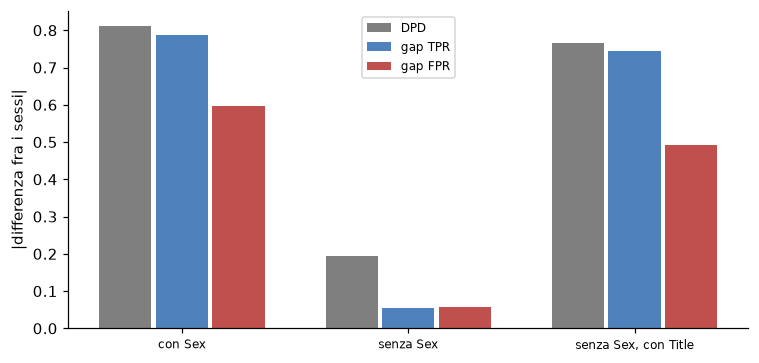

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def fit_predict(drop=(), title=False):
    A, B = enc.transform(tr, with_title=title).drop(columns=list(drop)), enc.transform(te, with_title=title).drop(columns=list(drop))
    sc = StandardScaler().fit(A); m = LogisticRegression(max_iter=1000).fit(sc.transform(A), ytr)
    return m.predict_proba(sc.transform(B))[:, 1]

summary = []
for name, kw in [("con Sex", {}), ("senza Sex", {"drop": ["Sex_female"]}), ("senza Sex, con Title", {"drop": ["Sex_female"], "title": True})]:
    yh = (fit_predict(**kw) >= 0.5).astype(int); gm = group_metrics(yte, yh, te.Sex.values)
    print(f"\n{name}: accuratezza {np.mean(yh == yte):.4f}")
    display(gm[["N", "TP", "FN", "FP", "TN", "base rate", "SR", "TPR", "FPR", "PPV", "Accuracy"]].round(3))
    for g, r in gm.iterrows():
        assert abs(r.SR - (r.FPR + (r.TPR - r.FPR) * r["base rate"])) < 1e-12   # SR = FPR + (TPR - FPR)·p
    summary.append({"modello": name, "accuratezza": np.mean(yh == yte), "DPD": gm.SR.max() - gm.SR.min(),
                    "DPR": gm.SR.min() / gm.SR.max(), "gap TPR": gm.TPR.max() - gm.TPR.min(), "gap FPR": gm.FPR.max() - gm.FPR.min()})
summary = pd.DataFrame(summary).set_index("modello"); display(summary.round(3))

fig, ax = plt.subplots(figsize=(7, 3.4)); x = np.arange(len(summary)); wd = 0.25
for k, (col, c) in enumerate([("DPD", GRAY), ("gap TPR", SURVIVED), ("gap FPR", DIED)]):
    ax.bar(x + (k - 1) * wd, summary[col], wd - 0.02, color=c, label=col)
ax.set_xticks(x, summary.index, fontsize=8); ax.set_ylabel("|differenza fra i sessi|"); ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 4. Post-processing: soglie per gruppo per uguagliare il TPR

Il training si divide di nuovo (70/30, stratificato): 436 per addestrare, 187 di validazione su cui scegliere le soglie. Bersaglio: il TPR globale di validazione con soglia 0,5. Il test serve solo per la valutazione finale.

In [7]:
from sklearn.model_selection import train_test_split
fit_tr, va = train_test_split(tr, test_size=0.3, stratify=tr.Survived, random_state=0)
e2 = Encoder().fit(fit_tr); Xf, Xv, Xt = e2.transform(fit_tr), e2.transform(va), e2.transform(te)
sc2 = StandardScaler().fit(Xf); m2 = LogisticRegression(max_iter=1000).fit(sc2.transform(Xf), fit_tr.Survived)
pv, pt = m2.predict_proba(sc2.transform(Xv))[:, 1], m2.predict_proba(sc2.transform(Xt))[:, 1]
yv = va.Survived.values
target = np.mean(pv[yv == 1] >= 0.5); print(f"{len(fit_tr)} addestramento, {len(va)} validazione; TPR bersaglio {target:.3f}")
thr = {}
for g in ["female", "male"]:
    m = (va.Sex == g).values; grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
    tprs = np.array([np.mean(pv[m & (yv == 1)] >= t) for t in grid])
    thr[g] = grid[np.argmin(np.abs(tprs - target))]
    print(f"{g}: {np.sum(m & (yv == 1))} positivi in validazione, soglia {thr[g]}, TPR {tprs[np.argmin(np.abs(tprs - target))]:.3f}")
for label, t in [("soglia 0,5 per tutti", {"female": 0.5, "male": 0.5}), ("soglie per gruppo", thr)]:
    yh = (pt >= te.Sex.map(t).values).astype(int)
    print(f"\n{label}: accuratezza test {np.mean(yh == yte):.4f}")
    display(group_metrics(yte, yh, te.Sex.values)[["SR", "TPR", "FPR", "PPV", "Accuracy"]].round(3))

436 addestramento, 187 validazione; TPR bersaglio 0.708
female: 50 positivi in validazione, soglia 0.67, TPR 0.700
male: 22 positivi in validazione, soglia 0.11, TPR 0.727

soglia 0,5 per tutti: accuratezza test 0.8097


,SR,TPR,FPR,PPV,Accuracy
male,0.058,0.156,0.035,0.500,0.815
female,0.842,0.930,0.583,0.825,0.800



soglie per gruppo: accuratezza test 0.5746


,SR,TPR,FPR,PPV,Accuracy
male,0.578,0.719,0.546,0.230,0.503
female,0.579,0.690,0.250,0.891,0.705
